# Lecture 11 – Text I: strings and regular expressions

QSS 20 · Modern Statistical Computing · Fall 2026

Content credit: see the course
[Acknowledgements](https://kengchichang.github.io/QSS20/acknowledgements).

### Agenda

1. **The patterns.** What a regular expression is, and its building blocks:
   concatenation, `|`, `*`, `( )`, `.`, `[ ]`, `+`, `?`, `{ }`, `\d`, `\w`,
   `\s`, `\`, `^`, `$`, and `\b`.
2. **The implementations.** Each `re` function next to the pandas `.str`
   method that does the same job.
3. **One implementation in full.** The e-scooter count from the lecture 10
   database, as a review of the patterns.

### Setup: imports and folders

Load every package the lecture uses, and name the data folder. `re` comes
with Python.

In [1]:
import re
import textwrap
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_rows', 20)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

DERIVED = Path('../../data/derived')

Exception reporting mode: Minimal


## Motivation: pull the emails out of a sign-up list

A student club exported its sign-up sheet as one string: each member's
name, then an email address in parentheses. The names and addresses are made
up.

In [2]:
# Three quotes start a string that runs over several lines.
signups = '''Maya Okafor (maya.r.okafor.27@dartmouth.edu)
Luis Ortega (luis.ortega.28@dartmouth.edu)
Samantha (Sam) Reyes (samantha.reyes.26@dartmouth.edu)
Priya Nair (priya.s.nair.27@dartmouth.edu)
Jonah Weiss (jonah.weiss.24@alumni.dartmouth.edu)
Grace Liu (grace.h.liu.25@alumni.dartmouth.edu)
Theo Brooks (theo.brooks@dartmouth.edu)
Amara Diallo (amara.diallo.28@dartmouth.edu)'''
signups

'Maya Okafor (maya.r.okafor.27@dartmouth.edu)\nLuis Ortega (luis.ortega.28@dartmouth.edu)\nSamantha (Sam) Reyes (samantha.reyes.26@dartmouth.edu)\nPriya Nair (priya.s.nair.27@dartmouth.edu)\nJonah Weiss (jonah.weiss.24@alumni.dartmouth.edu)\nGrace Liu (grace.h.liu.25@alumni.dartmouth.edu)\nTheo Brooks (theo.brooks@dartmouth.edu)\nAmara Diallo (amara.diallo.28@dartmouth.edu)'

- `signups` is one string. The `\n` in the printed value is the line break
  between members. `print(signups)` would show the eight lines.

### Method 1: cut the text at each `(` and `)`

Split the text at every `(`, then keep each piece up to the next `)`.

In [3]:
after_paren = signups.split('(')[1:]   # the text after each '('
[piece.split(')')[0] for piece in after_paren]

['maya.r.okafor.27@dartmouth.edu',
 'luis.ortega.28@dartmouth.edu',
 'Sam',
 'samantha.reyes.26@dartmouth.edu',
 'priya.s.nair.27@dartmouth.edu',
 'jonah.weiss.24@alumni.dartmouth.edu',
 'grace.h.liu.25@alumni.dartmouth.edu',
 'theo.brooks@dartmouth.edu',
 'amara.diallo.28@dartmouth.edu']

- `Sam` is in the list. The nickname sits in parentheses too, and `split`
  cuts at every parenthesis, whatever is inside.
- A fix would add an `if` that tests each piece for `@`. Each new shape in
  the data, a nickname, a missing year, or a second domain, adds another
  test.

### Method 2: describe the shape of an email with a regular expression

Find every piece of text that has the shape of an email address inside
parentheses.

In [4]:
re.findall(r'\(([\w.]+@[\w.]+)\)', signups)

['maya.r.okafor.27@dartmouth.edu',
 'luis.ortega.28@dartmouth.edu',
 'samantha.reyes.26@dartmouth.edu',
 'priya.s.nair.27@dartmouth.edu',
 'jonah.weiss.24@alumni.dartmouth.edu',
 'grace.h.liu.25@alumni.dartmouth.edu',
 'theo.brooks@dartmouth.edu',
 'amara.diallo.28@dartmouth.edu']

- One line, and `(Sam)` is out: it has no `@`, so it does not fit the shape.
- The pattern says what an address looks like: letters, digits, or periods,
  then `@`, then more of the same, between parentheses. It does not list the
  addresses, so an address added next week matches too.
- Part 1 teaches the pieces of this pattern. Part 2 returns to it and reads
  it piece by piece.

## Part 1: the patterns

### A regular expression describes a set of strings through a pattern

- A **regular expression** (regex) is a sequence of characters that
  specifies a search pattern.
- Example: `[0-9]{3}-[0-9]{2}-[0-9]{4}` reads as "3 of any digit, then a
  dash, then 2 of any digit, then a dash, then 4 of any digit". It describes
  every string with the shape of a US Social Security number, such as
  `123-45-6789`.
- Python's `re` module and the pandas `.str` methods read the same patterns.
  Many other languages and tools read them too, with small differences.

### Goals for regular expressions

The goal is **not** to memorize the language of regular expressions. Instead:

1. Understand what a regular expression can do.
2. Parse and create a pattern with a reference table at hand.
3. Use the vocabulary: metacharacter, escape character, character class,
   group, quantifier, anchor.
4. Tell `( )`, `[ ]`, and `{ }` apart.
5. Design your own character classes with `\d`, `\w`, `\s`, `[...-...]`,
   and `^`.
6. Use the Python and pandas methods that take a pattern.

[regex101.com](https://regex101.com) tests a pattern in the browser and
explains each part. Choose the **Python** flavor in the left sidebar.

### Test a pattern in Python

Two functions test a pattern on a string. Both take the pattern first and
the text second.

In [5]:
text = 'here is a string for you: ABBBA. here is another: ABBBBBBBA'
re.findall(r'AB*A', text)

['ABBBA', 'ABBBBBBBA']

In [6]:
words = ['AA', 'ABBA', 'AB', 'BA']
[w for w in words if re.search(r'AB*A', w)]

['AA', 'ABBA']

- `re.findall(pattern, text)` returns every piece of `text` that fits the
  pattern, as a list of strings, from left to right.
- `re.search(pattern, text)` tells whether the pattern fits **somewhere** in
  `text`. It returns a match object when it does and `None` when it does
  not, so `if re.search(...)` keeps the words that match.
- Write every pattern as a **raw string**, `r'...'`. Part 2 shows why.
- In every Matches / No match table below, a text **matches** when the
  pattern fits somewhere inside it, as `re.search` tests. To require the
  whole text to fit, use the anchors `^` and `$` at the end of this part.

### Four basic operations

| Operation | Pattern | Matches |
|---|---|---|
| **concatenation**: consecutive characters | `AABAAB` | `AABAAB` |
| <code>&#124;</code>: **or** | <code>AA&#124;BAAB</code> | `AA` or `BAAB` |
| `*`: **zero or more** of the piece before it | `AB*A` | `AA`, `ABA`, `ABBA`, ... |
| `( )`: **group**, so an operation applies to the whole group | `(AB)*A` | `A`, `ABA`, `ABABA`, ... |

- `*`, `( )`, and `|` are **metacharacters**: each represents an operation,
  not a literal text character.
- `A(A|B)AAB` combines three of them: `A`, then `A` or `B`, then `AAB`. It
  matches `AAAAB` and `ABAAB`.

### Order of operations: what matches and what does not

| Pattern | Operation | Order | Matches | No match |
|---|---|---|---|---|
| <code>A(A&#124;B)AAB</code> | group `( )` | 1 | `AAAAB`, `ABAAB` | `AABAB`, `ABBAB` |
| `(AB)*A` | group, then `*` | 1 | `A`, `ABABABABA` | `B`, `BB` |
| `AB*A` | `*` (zero or more) | 2 | `AA`, `ABBBBBBA` | `AB`, `BA` |
| `AABAAB` | concatenation | 3 | `AABAAB` | `AABAB` |
| <code>AA&#124;BAAB</code> | or <code>&#124;</code> | 4 | `AA`, `BAAB` | `ABAB` |

- Parentheses bind first, then `*`, then characters in a row, and `|`
  last. So `AA|BAAB` means `AA` or `BAAB`, not `A` then `A or B` then `AAB`.
- `(AB)*A` matches `A` because `*` allows zero copies of `AB`.

### ❓ Question

Which of these patterns match the string `ABBA`? Select all that apply.

- `AABAAB`
- `AA|BAAB`
- `AB*A`
- `(AB)*A`

<details><summary>Answer</summary>

**`AB*A` and `(AB)*A`.** `AB*A` matches the whole string: `A`, two `B`,
`A`. `(AB)*A` matches too, because `*` allows zero copies of `AB`, and the
`A` at the start fits (so does the `A` at the end). `AABAAB` needs six
characters in that order, and `AA|BAAB` needs `AA` or `BAAB`. Neither is
inside `ABBA`.

</details>

In [7]:
for pattern in [r'AABAAB', r'AA|BAAB', r'AB*A', r'(AB)*A']:
    print(pattern, re.search(pattern, 'ABBA'))

AABAAB None
AA|BAAB None
AB*A <re.Match object; span=(0, 4), match='ABBA'>
(AB)*A <re.Match object; span=(0, 1), match='A'>


- `re.search` shows where each match sits: `span=(0, 4)` is the whole
  string, `span=(0, 1)` the first `A` alone. `None` means no match.

### ❓ Question

Which pattern matches `moon`, `moooon`, and so on: an **even** number of
`o`, except zero? It must not match `mn` or `mooon`.

- `moo*n`
- `m(oo)*n`
- `moo(oo)*n`

<details><summary>Answer</summary>

**`moo(oo)*n`.** `moo*n` matches `mon` and `mooon`: the `*` repeats only the
second `o`, so any count of one or more works. `m(oo)*n` allows zero pairs,
so it matches `mn`. `moo(oo)*n` requires one pair, then any number of extra
pairs. Try it at [regex101.com/r/8tkQ23/1](https://regex101.com/r/8tkQ23/1).

</details>

In [8]:
moons = ['mn', 'mon', 'moon', 'mooon', 'moooon']
for pattern in [r'moo*n', r'm(oo)*n', r'moo(oo)*n']:
    print(pattern, [m for m in moons if re.search(pattern, m)])

moo*n ['mon', 'moon', 'mooon', 'moooon']
m(oo)*n ['mn', 'moon', 'moooon']
moo(oo)*n ['moon', 'moooon']


### Six more operations

| Operation | Pattern | Matches |
|---|---|---|
| `.`: **any one character** (except a line break) | `.U.U.U.` | `CUMULUS`, `JUGULUM` |
| `[ ]`: **one character from a class** | `[A-Za-z]` | `A`, `a`, `B`, `b`, ... |
| `+`: **one or more** | `AB+` | `AB`, `ABB`, `ABBB`, ... |
| `?`: **zero or one** | `AB?` | `A`, `AB` |
| `{x}`: **exactly x times** | `AB{2}` | `ABB` |
| `{x,y}`: **between x and y times** | `AB{0,2}` | `A`, `AB`, `ABB` |

- `*`, `+`, and `?` are short forms of `{ }`: `*` is `{0,}`, `+` is `{1,}`,
  and `?` is `{0,1}`.
- `*`, `+`, `?`, and `{ }` are **quantifiers**. A quantifier follows a
  character, a class, or a group, and says how many times that piece may
  repeat.

### A quantifier repeats one piece

Find the first match of `ha+` and of `(ha)+` in a laugh.

In [9]:
(re.search(r'ha+', 'hahaha').group(),
 re.search(r'(ha)+', 'hahaha').group())

('ha', 'hahaha')

- `.group()` is the text that the first match covers. `ha+` repeats only
  the `a`, so its match stops after the first `ha`. `(ha)+` repeats the
  pair, so its match covers `hahaha`.
- A quantifier applies to the one character, class, or group right before
  it.

### Character classes

A **character class** describes a set of characters. The pattern matches
**one** character from the set.

| Class | Matches one |
|---|---|
| `[A-Z]` | any upper-case letter from A to Z |
| `[0-9]` | any digit from 0 to 9 |
| `[A-Za-z0-9]` | any letter or digit |
| `[aeiou]` | one lower-case vowel |
| `[- ]` | a hyphen or a space |

- `-` between two characters makes a **range**. A hyphen first or last in
  the class is a literal, as in `[- ]`.
- `^` right after `[` **negates** the class: `[^A-Z]` matches any character
  that is not an upper-case letter.
- Inside `[ ]`, the other metacharacters are literals: `[.]` matches a
  period, and `[(]` an opening parenthesis.

### Shorthand classes

A backslash and a letter name a common class.

| Shorthand | Matches one | Same as |
|---|---|---|
| `\d` | digit | `[0-9]` |
| `\w` | word character: letter, digit, or `_` | `[A-Za-z0-9_]` |
| `\s` | white space: space, tab, or line break | `[ \t\n]` |
| `.` | any character except a line break | |

- The capital letter negates the class: `\D` is any character except a
  digit, `\S` anything except white space, and `\W` anything except a word
  character.
- A shorthand works inside `[ ]` too: `[\w.]` is a word character or a
  period, the class in the email pattern.

### Classes and quantifiers: what matches and what does not

| Pattern | Means | Matches | No match |
|---|---|---|---|
| `.U.U.U.` | any, `U`, any, `U`, any, `U`, any | `CUMULUS`, `JUGULUM` | `SUCCUBUS`, `TUMULTUOUS` |
| `[A-Z][a-z]+` | a capital, then one or more lower-case letters | `Capitalized`, `camelCase` | `word`, `ALLCAPS`, `4illegal` |
| `j[aeiou]{3}hn` | `j`, exactly three vowels, `hn` | `jaoehn`, `jooohn` | `jhn`, `jaeiouhn` |
| `j[ou]{1,2}hn` | `j`, one or two of `o` or `u`, `hn` | `john`, `juohn` | `jhn`, `jooohn` |
| `jo+hn` | `j`, one or more `o`, `hn` | `john`, `joooooohn` | `jhn`, `jahn` |
| `\d{3}-\d{2}-\d{4}` | three digits, dash, two, dash, four | `123-45-6789` | `123-456-789` |

- `[A-Z][a-z]+` matches `camelCase` because `Case` is inside it. A match
  needs the pattern somewhere in the text, not everywhere.

### ❓ Question

Choose a cleaner solution to the `moon` question. Which pattern matches an
even number of `o`, except zero?

- `m(oo)+n`
- `mo{2}n`
- `moo.oon`

<details><summary>Answer</summary>

**`m(oo)+n`.** `+` requires one or more pairs. `mo{2}n` matches only
`moon`, and `moo.oon` requires exactly five characters between `m` and `n`,
of which the middle one can be anything, so it matches `mooxoon` and misses
`moon`.

</details>

In [10]:
for pattern in [r'm(oo)+n', r'mo{2}n', r'moo.oon']:
    print(pattern, [m for m in moons if re.search(pattern, m)])

m(oo)+n ['moon', 'moooon']
mo{2}n ['moon']
moo.oon []


### ❓ Question

What pattern matches a lower-case word with a **repeated vowel**: `noon`,
`peel`, `festoon`, `loop`, `oodles`, and so on?

- `.*[aeiou]+.*`
- `[a-z]*(aa|ee|ii|oo|uu)[a-z]*`

<details><summary>Answer</summary>

**The second.** `[aeiou]+` means one or more vowels of any kind, so
`.*[aeiou]+.*` matches `moan` and `bike`. `(aa|ee|ii|oo|uu)` requires the
same vowel twice in a row.

</details>

In [11]:
vowels = ['noon', 'peel', 'festoon', 'loop', 'oodles', 'moan', 'bike']
for pattern in [r'.*[aeiou]+.*', r'[a-z]*(aa|ee|ii|oo|uu)[a-z]*']:
    print(pattern, [v for v in vowels if re.search(pattern, v)])

.*[aeiou]+.* ['noon', 'peel', 'festoon', 'loop', 'oodles', 'moan', 'bike']
[a-z]*(aa|ee|ii|oo|uu)[a-z]* ['noon', 'peel', 'festoon', 'loop', 'oodles']


### Greediness: `.*` takes the longest possible match

Find each `<div>...</div>` element in a sentence.

In [12]:
html = ('This is a <div>example</div> of greediness '
        '<div>in</div> regular expressions.')
re.findall(r'<div>.*</div>', html)

['<div>example</div> of greediness <div>in</div>']

- In English, the pattern says: the exact string `<div>`, then any character
  zero or more times, then the exact string `</div>`.
- One match, from the first `<div>` to the last `</div>`. A quantifier is
  **greedy**: it takes as many characters as it can and still lets the rest
  of the pattern fit.

### `?` after a quantifier makes it lazy

Add `?` after `*`, and search again.

In [13]:
re.findall(r'<div>.*?</div>', html)

['<div>example</div>', '<div>in</div>']

- `.*?` is **lazy**: it takes as few characters as possible, so each match
  ends at the first `</div>`. Two matches.
- This is the second meaning of `?`. After a character or group it means
  "zero or one". After a quantifier it means "as few as possible".
  Try it at [regex101.com/r/HATiTH/1](https://regex101.com/r/HATiTH/1).

### The last set: escape, start, and end

| Pattern | Operation | Matches | No match |
|---|---|---|---|
| `a\*b` | `\`: **read the next character literally** | `a*b` | `aaab` |
| `^abc` | `^`: **the start** of the string | `abc 123` | `123 abc` |
| `abc$` | `$`: **the end** of the string | `123 abc` | `abc 123` |

- `^` and `$` are **anchors**: they match a position, not a character.
  `^abc$` means the whole string is `abc`.
- `^` has a different job inside a character class: `[^abc]` is any
  character except `a`, `b`, or `c`.
- Python's `re` has 14 metacharacters: `. ^ $ * + ? { } [ ] \ | ( )`. To
  match one of them as text, put `\` before it.

### Anchors and escapes: what matches and what does not

| Pattern | Means | Matches | No match |
|---|---|---|---|
| `^ark` | the text starts with `ark` | `ark two`, `ark o ark` | `dark` |
| `ark$` | the text ends with `ark` | `dark`, `ark o ark` | `ark two` |
| `^ark$` | the whole text is `ark` | `ark` | `dark`, `ark two` |
| `cow\.com` | a period, then `com` | `cow.com` | `cowscom`, `cow-com` |
| `cow.com` | any character, then `com` | `cow.com`, `cowscom` | `cowcom` |
| `\(27\)` | `27` inside parentheses | `(27)` | `27`, `.27@` |
| `(27)` | a group that holds `27` | `27`, `.27@` | `2 7` |

- Without the escape, `.` and `( )` do their jobs: `cow.com` also matches
  `cowscom`, and `(27)` matches `27` with no parentheses around it.

### `\b`: the edge of a word

List the words that contain `bike` as a whole word.

In [14]:
bikes = ['bike', 'e-bike', 'dirt bike', 'motorbike', 'bikes']
[b for b in bikes if re.search(r'\bbike\b', b)]

['bike', 'e-bike', 'dirt bike']

- `\b` matches a **word boundary**: a position between a word character
  (`\w`) and anything else, or the start or end of the string. Like `^` and
  `$`, it matches a position, not a character.
- `motorbike` fails, because `r` and `b` are both word characters. `e-bike`
  matches, because a hyphen is not a word character: `\b` sees a word edge
  after `e-`.

### Part 1 summary: the parts of a pattern

| Pattern | Means |
|---|---|
| `AABAAB` | literals: these characters, in this order |
| <code>AA&#124;BAAB</code> | `AA` or `BAAB`; <code>&#124;</code> binds last |
| `(AB)*A` | a group; a quantifier after it repeats the whole group |
| `*`, `+`, `?`, `{2}`, `{1,2}` | zero or more; one or more; zero or one; exactly two; one or two |
| `[A-Z]`, `[aeiou]`, `[^0-9]`, `[- ]` | one character from a class; a range; a negated class; a hyphen or a space |
| `\d`, `\w`, `\s`, `.` | digit; word character; white space; any character |
| `.*`, `.*?` | as many characters as possible; as few as possible |
| `\.`, `\(`, `\*` | a literal `.`, `(`, `*` |
| `^`, `$`, `\b` | start; end; word boundary |

- Order of operations: parentheses, then quantifiers, then characters in a
  row, then `|`.

## Part 2: the implementations

### Python string methods, without a pattern

Lower the letters of one value, remove its space, test its first letter,
and test whether it contains `SCOO`.

In [15]:
name = 'E- SCOOTER'
(name.lower(), name.replace(' ', ''),
 name.startswith('E'), 'SCOO' in name)

('e- scooter', 'E-SCOOTER', True, True)

- A method returns a new string. `name` itself does not change.
- `in` tests whether one string contains another. Every test is exact: `'e'`
  and `'E'` are different characters.
- When the text you look for is fixed, these methods are enough and easier
  to read than a pattern.

### `.replace` against `.str.replace` on a pandas column

Three values contain the word `Bike`. Replace `Bike` with `Bicycle`, first
with the Series method `.replace`, then with `.str.replace`.

In [16]:
bikes = pd.Series(['Bike', 'E-Bike', 'Dirt Bike'])
bikes.replace('Bike', 'Bicycle')

0      Bicycle
1       E-Bike
2    Dirt Bike
dtype: object

In [17]:
bikes.str.replace('Bike', 'Bicycle')

0         Bicycle
1       E-Bicycle
2    Dirt Bicycle
dtype: object

- `Series.replace` compares whole values, as `==` does: it swaps the value
  `Bike` and leaves `E-Bike` and `Dirt Bike` alone. It works like a lookup
  table.
- `.str` is an **accessor**: it applies a string method to each value of a
  Series. `.str.replace` edits the text inside every value, as
  `name.replace` did for one string, so all three values change.

### Raw strings: write every pattern as `r'...'`

Find the folder name `\new` in a Windows path, first with a normal string,
then with a raw string.

In [18]:
path = 'Folder path: C:\\new_folder'
print(path)
re.findall('\\new', path)

Folder path: C:\new_folder


[]

In [19]:
re.findall(r'\\new', path)

['\\new']

- Python reads a normal string first: `'\\new'` becomes `\new`, and `re`
  then reads `\n` as a line break followed by `ew`. The path has no line
  break, so the list is empty, with no error.
- A **raw string**, with `r` before the quotes, keeps every backslash as it
  is. `r'\\new'` reaches `re` as `\\new`: an escaped backslash, then `new`.
- The same happens to `\b`: in a normal string it is one character, a
  backspace. Compare `len('\b')` and `len(r'\b')`.

In [20]:
len('\b'), len(r'\b')

(1, 2)

### Extraction: `re.findall` and `.str.findall`

Find every Social Security number in one string, then in each value of a
column. The numbers are made up.

In [21]:
text = ("My social security number is 123-45-6789 bro, "
        "or actually maybe it's 321-45-6789.")
pattern = r'[0-9]{3}-[0-9]{2}-[0-9]{4}'
re.findall(pattern, text)

['123-45-6789', '321-45-6789']

In [22]:
ssn = pd.Series(['987-65-4321', 'no number here', text,
                 '999-99-9999', None], name='SSN')
ssn.str.findall(pattern)

0                 [987-65-4321]
1                            []
2    [123-45-6789, 321-45-6789]
3                 [999-99-9999]
4                          None
Name: SSN, dtype: object

- `re.findall(pattern, text)` returns a list of every match in one string.
- `Series.str.findall(pattern)` runs it on every value and returns a Series
  of lists: an empty list where nothing matches. The missing value stays
  missing.
- A **match** is a piece of the text that fits the pattern.

### Search: `re.search` and `.str.contains`

Search one string for the first number, then test each value of the column.

In [23]:
first = re.search(pattern, text)
first

<re.Match object; span=(29, 40), match='123-45-6789'>

In [24]:
first.group(), first.start()

('123-45-6789', 29)

In [25]:
print(re.search(pattern, 'no number here'))

None


- `re.search(pattern, text)` scans `text` from the left and stops at the
  first place where the pattern fits. It returns a **match object**:
  `.group()` is the text that matched, and `.start()` its position.
- With no match, `re.search` returns `None`.

In [26]:
ssn.str.contains(pattern, na=False)

0     True
1    False
2     True
3     True
4    False
Name: SSN, dtype: bool

- `.str.contains(pattern)` runs `re.search` on each value and returns `True`
  or `False`. The missing value would give `NaN`, which pandas refuses to
  filter with. `na=False` counts it as no match.

### Capture groups: `( )` keeps part of each match

Earlier, parentheses set the order of operations. With `re.findall` and
`.str.extract` they have a second job: a **capture group** returns only the
part of the match inside it.

In [27]:
when = 'I will meet you at 08:30:00 pm tomorrow'
re.findall(r'(\d\d):(\d\d):(\d\d)', when)

[('08', '30', '00')]

In [28]:
emails = ('my old email was kc@ucsd.edu, '
          'my new email is kc@dartmouth.edu')
(re.findall(r'\w+@\w+\.edu', emails),
 re.findall(r'\w+@(\w+)\.edu', emails))

(['kc@ucsd.edu', 'kc@dartmouth.edu'], ['ucsd', 'dartmouth'])

- The whole pattern still decides where a match is. With one group,
  `re.findall` returns the group's text. With two or more groups, it
  returns one tuple per match, with one item per group, in order.
- Without a group, `re.findall` returns each whole match.

### `.str.extract` and `.str.extractall`: one column per group

Split each number in the column into its three parts.

In [29]:
pattern_cg = r'([0-9]{3})-([0-9]{2})-([0-9]{4})'
ssn.str.extract(pattern_cg)

,0,1,2
0,987,65,4321
1,NaN,NaN,NaN
2,123,45,6789
3,999,99,9999
4,NaN,NaN,NaN


In [30]:
ssn.str.extractall(pattern_cg)

0   1     2
  match               
0 0      987  65  4321
2 0      123  45  6789
  1      321  45  6789
3 0      999  99  9999

- `.str.extract` returns a DataFrame with one column per group and one row
  per value, from the **first** match in each value: `NaN` where nothing
  matches.
- `.str.extractall` returns every match, with a two-level index: the row of
  the value and the number of the match within it. The row with two numbers
  gives two matches.
- With no capture group, `.str.extract` raises a `ValueError`.

### `(?:...)`: a group that does not capture

With `re.findall`, every pair of parentheses captures. Keep the group but
drop the capture with `?:`.

In [31]:
# A repeated vowel, then three digits. Only the digits are wanted...
re.findall(r'(aa|ee|ii|oo|uu)(\d{3})', 'eeoo124')

[('oo', '124')]

In [32]:
re.findall(r'(?:aa|ee|ii|oo|uu)(\d{3})', 'eeoo124')

['124']

- `(?:...)` groups like plain parentheses, for `|` or a quantifier, but
  captures nothing, so `re.findall` returns the digits only.
- `.str.contains` warns when a pattern has a capture group it cannot use.
  `(?:...)` removes the warning, so the rules in Part 3 use it.

### Substitution: `re.sub` and `.str.replace(regex=True)`

Remove every HTML tag from one string, then from each value of a column.

In [33]:
tagged = '<div><td valign="top">Moo</td></div>'
re.sub(r'<[^>]+>', '', tagged)

'Moo'

In [34]:
html_col = pd.Series([tagged, '<a href="x">Link</a>',
                      '<b>Bold text</b>'], name='Html')
html_col.str.replace(r'<[^>]+>', '', regex=True)

0          Moo
1         Link
2    Bold text
Name: Html, dtype: object

- `<[^>]+>` is `<`, then one or more characters that are not `>`, then `>`:
  one tag. `re.sub(pattern, replacement, text)` replaces every match with
  `replacement`. An empty replacement deletes each match.
- `.str.replace` reads its first argument as plain text, as on the
  `Bicycle` slide. `regex=True` makes it a pattern. `.str.contains`,
  `.str.findall`, and `.str.extract` need no such flag.

### Split: `re.split` and `.str.split`

Cut one address at every period or `@`, then every value of a column.

In [35]:
re.split(r'[.@]', 'maya.r.okafor.27@dartmouth.edu')

['maya', 'r', 'okafor', '27', 'dartmouth', 'edu']

In [36]:
addresses = pd.Series(['maya.r.okafor.27@dartmouth.edu',
                       'theo.brooks@dartmouth.edu'])
addresses.str.split(r'[.@]', regex=True)

0    [maya, r, okafor, 27, dartmouth, edu]
1           [theo, brooks, dartmouth, edu]
dtype: object

- Both cut at every match and drop the matched text, so the periods and the
  `@` are gone. `str.split` without `re` cuts at one fixed string.

### Capitals: `flags=re.IGNORECASE` and `case=False`

Find `sam` in the sign-up list, with and without capitals ignored, then test
a column.

In [37]:
(re.findall(r'sam', signups),
 re.findall(r'sam', signups, flags=re.IGNORECASE))

(['sam'], ['Sam', 'Sam', 'sam'])

In [38]:
names = pd.Series(['Sam', 'samantha', 'SAMUEL', 'Maya'])
names.str.contains('sam', case=False)

0     True
1     True
2     True
3    False
dtype: bool

- Without the flag, only the `sam` in `samantha.reyes` matches. With it,
  the `Sam` in `(Sam)` and in `Samantha` match too.
- `flags` are options that change how `re` reads the whole pattern. The
  pandas `.str` methods that take a pattern also take `flags=`, and
  `.str.contains` and `.str.replace` take `case=False`, which does the same.

### String function summary 🌟

| Base Python | `re` | pandas `.str` |
|---|---|---|
| `s.lower()`, `s.upper()` | | `ser.str.lower()`, `ser.str.upper()` |
| `s.replace(...)` | `re.sub(...)` | `ser.str.replace(..., regex=True)` |
| `s.split(...)` | `re.split(...)` | `ser.str.split(..., regex=True)` |
| `s[1:4]` | | `ser.str[1:4]` |
| | `re.findall(...)` | `ser.str.findall(...)`, `ser.str.extract(...)`, `ser.str.extractall(...)` |
| `'ab' in s` | `re.search(...)` | `ser.str.contains(...)` |
| `len(s)` | | `ser.str.len()` |
| `s.strip()` | | `ser.str.strip()` |

- Base Python methods take fixed text. `re` functions take a pattern and one
  string. The `.str` methods take either, on every value of a column.

### Back to the sign-up list: read the pattern piece by piece

The pattern of Method 2, `\(([\w.]+@[\w.]+)\)`, in order:

| Piece | Kind | Matches |
|---|---|---|
| `\(` | escaped metacharacter | a literal `(` |
| `(` | metacharacter | starts the capture group, the text `findall` returns |
| `[\w.]+` | class and quantifier | one or more word characters or periods, such as `maya.r.okafor.27` |
| `@` | literal | `@` |
| `[\w.]+` | class and quantifier | `dartmouth.edu` or `alumni.dartmouth.edu` |
| `)` | metacharacter | ends the capture group |
| `\)` | escaped metacharacter | a literal `)` |

- The pattern has one capture group, so `re.findall` returns the group's
  text, and the parentheses around each address are left out.
- `[\w.]+` stops at the `)`, because `)` is not in the class.

### ❓ Question

```python
re.findall(r'\((\w+@\w+)\)', signups)
```

This pattern drops the periods from both classes. What does it return?

<details><summary>Answer</summary>

**An empty list, `[]`.** `\w` does not match a period, and every address has
at least one, in `dartmouth.edu`. No address fits between the parentheses.

</details>

### Two capture groups on the sign-up list

Capture each member's class year, the two digits between a period and the
`@`, and the domain. Put the matches in a DataFrame.

In [39]:
year_domain = re.findall(r'\.(\d{2})@([\w.]+)', signups)
print(year_domain[:2])
pd.DataFrame(year_domain, columns=['year', 'domain'])

[('27', 'dartmouth.edu'), ('28', 'dartmouth.edu')]


,year,domain
0,27,dartmouth.edu
1,28,dartmouth.edu
2,26,dartmouth.edu
3,27,dartmouth.edu
4,24,alumni.dartmouth.edu
5,25,alumni.dartmouth.edu
6,28,dartmouth.edu


- Each tuple becomes a row, and each group a column.
- Eight members give seven rows. `theo.brooks@dartmouth.edu` has no class
  year, so the pattern finds no match in it.

### Greedy and lazy on the sign-up list

Find each parenthesized piece with "a `(`, any characters, a `)`", first
greedy, then lazy.

In [40]:
re.findall(r'\(.*\)', signups)

['(maya.r.okafor.27@dartmouth.edu)',
 '(luis.ortega.28@dartmouth.edu)',
 '(Sam) Reyes (samantha.reyes.26@dartmouth.edu)',
 '(priya.s.nair.27@dartmouth.edu)',
 '(jonah.weiss.24@alumni.dartmouth.edu)',
 '(grace.h.liu.25@alumni.dartmouth.edu)',
 '(theo.brooks@dartmouth.edu)',
 '(amara.diallo.28@dartmouth.edu)']

In [41]:
re.findall(r'\(.*?\)', signups)

['(maya.r.okafor.27@dartmouth.edu)',
 '(luis.ortega.28@dartmouth.edu)',
 '(Sam)',
 '(samantha.reyes.26@dartmouth.edu)',
 '(priya.s.nair.27@dartmouth.edu)',
 '(jonah.weiss.24@alumni.dartmouth.edu)',
 '(grace.h.liu.25@alumni.dartmouth.edu)',
 '(theo.brooks@dartmouth.edu)',
 '(amara.diallo.28@dartmouth.edu)']

In [42]:
len(re.findall(r'\(.*\)', signups, flags=re.DOTALL))

1

- Greedy: eight matches, one per line, because `.` does not cross a line
  break. On the `Samantha (Sam) Reyes` line, the match runs from the first
  `(` to the last `)`, with the nickname, the name, and the address inside.
- Lazy: nine matches, each ending at the first `)`. These are the pieces
  that Method 1 cut out, `(Sam)` included. Method 2 kept `(Sam)` out by
  naming the shape, with `@` in the middle.
- The flag `re.DOTALL` lets `.` cross a line break. The greedy pattern then
  returns one match, from the first `(` to the last `)` of the whole string.

## Part 3: one implementation in full

### E-bikes, e-scooters, and mopeds in fatal crashes

- NY1 [reported on 5 March 2024](https://ny1.com/nyc/manhattan/traffic_and_transit/2024/03/06/bike-deaths-in-the-city-are-at-a-23-year-high--report-says)
  that 30 cyclists died in New York City in 2023, according to the city's
  Department of Transportation. 23 of them rode e-bikes.
- That count covers riders. An e-bike, an e-scooter, or a moped can also be
  in a crash that kills a pedestrian or a driver.

> **How many of New York's fatal crashes involved an e-bike, an e-scooter, or
> a moped, and did that number grow?**

- The vehicles table from lecture 10 lists every vehicle in each fatal crash.
  The vehicle type is typed into the police report. Read this part as a
  worked implementation: at each step, name the pattern piece from Part 1
  and the method from Part 2 that does the work.

### Read each vehicle with the year of its crash

Open the lecture 10 database without changing it, join each vehicle to the
year of its crash, and close the file.

In [43]:
db_file = DERIVED / 'traffic.duckdb'
print(db_file.exists())   # False: run lecture 10's notebook first

con = duckdb.connect(str(db_file), read_only=True)
vehicles = con.sql('''
SELECT v.collision_id, year(c.crash_date) AS year, v.vehicle_type
FROM vehicles AS v
JOIN crashes AS c USING (collision_id)
''').df()
con.close()   # the table is now in pandas
vehicles.shape

True


(5961, 3)

- `read_only=True` opens the file for reading only. This lecture changes
  nothing in it.
- One row per vehicle: 5,961 vehicles in the fatal crashes, each with the
  year of its crash.

### Count and list the spellings of vehicle type

Count the different values and the vehicles with no type, then list the
values from most to least common.

In [44]:
(vehicles['vehicle_type'].nunique(),
 vehicles['vehicle_type'].isna().sum())

(93, 276)

In [45]:
vehicles['vehicle_type'].value_counts()

vehicle_type
Station Wagon/Sport Utility Vehicle    1348
Sedan                                  1247
PASSENGER VEHICLE                       584
SPORT UTILITY / STATION WAGON           360
Motorcycle                              319
                                       ... 
Boom Lift                                 1
MOPED                                     1
LIMO                                      1
BACKHOE                                   1
E-Sco                                     1
Name: count, Length: 93, dtype: int64

- 93 different spellings, and 276 vehicles with no type.
- The common types come in two styles: `Sedan` and `PASSENGER VEHICLE`. Many
  rare values appear once, such as `E-Sco`, `MOPED`, and `LIMO`.

### Count the exact spelling `E-Bike`

Count the vehicles recorded as exactly `E-Bike`.

In [46]:
(vehicles['vehicle_type'] == 'E-Bike').sum()

131

- `==` compares whole values: 131 vehicles are recorded as `E-Bike`. Every
  other spelling counts as something else.

### ❓ Question

These seven values are in the table:

`E-Bike`, `E-Bik`, `Bike`, `Motorbike`, `E-Scooter`, `ESCOOTER S`,
`Motorscooter`

Which ones does `== 'E-Bike'` miss, and which belong in a count of e-bikes,
e-scooters, and mopeds?

<details><summary>Answer</summary>

`== 'E-Bike'` finds only `E-Bike`. `E-Bik` looks like an e-bike cut short.
`E-Scooter` and `ESCOOTER S` are e-scooters, and `Motorscooter` is a motor
scooter, which this lecture counts with mopeds. `Bike` is a pedal bike and
`Motorbike` a motorcycle: neither belongs in the count, though later slides
give each its own class for comparison.

</details>

### `.str.contains`: find a word in every value

Find the vehicle types that contain `scooter`, capitals ignored, and count
each spelling that the test keeps.

In [47]:
types = vehicles['vehicle_type']
has_scooter = types.str.contains('scooter', case=False, na=False)
types[has_scooter].value_counts()

vehicle_type
E-Scooter       32
Motorscooter    23
SCOOTER          2
ESCOOTER S       1
E-SCOOTER        1
E- SCOOTER       1
Name: count, dtype: int64

- `scooter` finds four spellings of e-scooter, and also `Motorscooter` and
  `SCOOTER`. It misses `E SCO` and `E-Sco`, which stop before the word ends.
- To cover every spelling with exact methods, you would list each one, and a
  new spelling next month would break the list. A pattern that describes the
  shape of the word does not need the list.

### Review: test a pattern on every recorded spelling

Put the 93 spellings in a Series, and list the ones that contain `E-Sco`,
capitals ignored.

In [48]:
spellings = pd.Series(
    sorted(vehicles['vehicle_type'].dropna().unique()))
spellings[spellings.str.contains(r'E-Sco', case=False)].tolist()

['E-SCOOTER', 'E-Sco', 'E-Scooter']

- `spellings[...]` keeps the values where `.str.contains` is `True`, and
  `.tolist()` prints them on one line.
- `E-Sco` is all literals, and the hyphen is a literal too. `E- SCOOTER` has
  a space after the hyphen, `E SCO` a space instead, and `ESCOOTER S`
  nothing. All three are e-scooters the pattern misses.

### ❓ Question

Which piece from Part 1 lets one pattern match `E-SCO`, `E SCO`, `E- SCO`,
and `ESCO`: any number of hyphens or spaces between `E` and `SCO`, including
none?

<details><summary>Answer</summary>

**A character class and `*`.** `[- ]` is one hyphen or one space. `[- ]*`
is zero or more of them. `E[- ]*SCO` covers all four spellings. `E[- ]SCO`
alone would require exactly one character, so `ESCO` and `E- SCO` would
still fail.

</details>

In [49]:
spellings[spellings.str.contains(r'E[- ]SCO', case=False)].tolist()

['E SCO', 'E-SCOOTER', 'E-Sco', 'E-Scooter']

In [50]:
spellings[spellings.str.contains(r'E[- ]*SCO', case=False)].tolist()

['E SCO', 'E- SCOOTER', 'E-SCOOTER', 'E-Sco', 'E-Scooter', 'ESCOOTER S']

- `[- ]` adds `E SCO`. `[- ]*` adds `E- SCOOTER` and `ESCOOTER S`: all six
  recorded e-scooter spellings match. `ELECTRIC S` does not.

### Review: `|` and the order of operations

Look for e-scooters and e-bikes with one pattern, first without parentheses,
then with them.

In [51]:
spellings[spellings.str.contains(r'E[- ]*SCO|BIK', case=False)].tolist()

['Bike',
 'Dirt Bike',
 'E SCO',
 'E- SCOOTER',
 'E-Bik',
 'E-Bike',
 'E-SCOOTER',
 'E-Sco',
 'E-Scooter',
 'ESCOOTER S',
 'Minibike',
 'Motorbike']

In [52]:
spellings[spellings.str.contains(r'E[- ]*(?:SCO|BIK)',
                                 case=False)].tolist()

['E SCO',
 'E- SCOOTER',
 'E-Bik',
 'E-Bike',
 'E-SCOOTER',
 'E-Sco',
 'E-Scooter',
 'ESCOOTER S']

- `|` binds last, so the first pattern means `E[- ]*SCO` or `BIK`. `BIK`
  alone finds every bike and motorbike: **false positives**, matched but not
  e-bikes.
- Parentheses limit the choice to the part inside them. The second pattern
  needs the `E` before `SCO` or `BIK`. `(?:...)` groups without capturing,
  so pandas raises no warning.

### Review: `^`, `$`, and `\b` keep a pedal bike apart

Pedal bikes are a separate class. List the spellings that contain `Bike`,
then the ones that are exactly `Bike`, then the ones with `bike` as a whole
word.

In [53]:
spellings[spellings.str.contains(r'Bike')].tolist()

['Bike', 'Dirt Bike', 'E-Bike']

In [54]:
spellings[spellings.str.contains(r'^Bike$')].tolist()

['Bike']

In [55]:
spellings[spellings.str.contains(r'\bbike\b', case=False)].tolist()

['Bike', 'Dirt Bike', 'E-Bike']

- `^Bike$` means the whole value is `Bike`. Without anchors, `Bike` also
  matches inside `E-Bike` and `Dirt Bike`.
- `\bbike\b` keeps `E-Bike` and `Dirt Bike` (a word edge sits after `E-`
  and after the space) and drops `Motorbike` and `Minibike`.

### Why the rules match the start of a word: the ten-character cut

Find the values whose length is ten.

In [56]:
type_length = vehicles['vehicle_type'].str.len()
vehicles.loc[type_length == 10, 'vehicle_type'].unique()

array(['MOTORCYCLE', 'Motorcycle', 'towe truck', 'Backhoe Lo',
       'ELECTRIC S', 'ESCOOTER S', 'Motor Scoo', 'E- SCOOTER',
       'Pickup Tru', 'WOOD CHIPP', 'Fire Appar', 'Standing S',
       'FIRE TRUCK', '4 dr sedan', '2 dr sedan'], dtype=object)

- `Motorcycle` and `4 dr sedan` are complete. `ESCOOTER S`, `Motor Scoo`,
  `ELECTRIC S`, `Standing S`, `Pickup Tru`, and `Fire Appar` stop in the
  middle of a word.
- The typed values seem to be cut at ten characters. A rule must match the
  start of a word, such as `SCO` or `SCOO`, not the whole word.

### Label each vehicle with the class its type matches

Write one pattern per class. Besides the three classes in the question,
label motorcycles and pedal bicycles, so that the counts can be compared.
Then run each rule over the column and write the class where it matches.

In [57]:
class_rules = {
    'e-bike':     r'^E[- ]*BIK',
    'e-scooter':  r'^(?:E[- ]*SCO|ELECTRIC S)',
    'moped':      r'^(?:MOPED|MOTOR ?SCOO)',
    'motorcycle': r'^(?:MOTOR|MINI)(?:CYCLE|BIKE)$|^DIRT BIKE$',
    'bicycle':    r'^(?:BIKE|BICYCLE)$',
}

vehicles['vehicle_class'] = None
for name, pattern in class_rules.items():
    hit = vehicles['vehicle_type'].str.contains(pattern, case=False,
                                                na=False)
    vehicles.loc[hit, 'vehicle_class'] = name

vehicles['vehicle_class'].value_counts()

vehicle_class
motorcycle    467
bicycle       221
e-bike        133
moped          84
e-scooter      38
Name: count, dtype: int64

- The loop takes each rule in turn: `.str.contains` marks the vehicles that
  match, and `.loc` writes the rule's name in those rows. A vehicle that no
  rule matches keeps `None`.
- No type matches two rules, so the order of the rules does not change the
  labels here.

- Read each rule with Part 1. `^` anchors the start. `(?:MOTOR|MINI)` is a
  group with `|` inside it. `?` in `MOTOR ?SCOO` makes the space optional.
  `$` in the bicycle rule keeps `Bike` apart from `E-Bike` and `Dirt Bike`.
- The moped class includes motor scooters. The police types do not say
  whether a moped or a motor scooter is electric.

### List the spellings that each rule caught

List the recorded spellings in each class, with their counts.

In [58]:
caught = (vehicles.groupby('vehicle_class')['vehicle_type']
          .value_counts())
print(caught.to_string())

vehicle_class  vehicle_type
bicycle        Bike            162
               BICYCLE          59
e-bike         E-Bike          131
               E-Bik             2
e-scooter      E-Scooter        32
               E SCO             1
               E- SCOOTER        1
               E-SCOOTER         1
               E-Sco             1
               ELECTRIC S        1
               ESCOOTER S        1
moped          Moped            59
               Motorscooter     23
               MOPED             1
               Motor Scoo        1
motorcycle     Motorcycle      319
               MOTORCYCLE      120
               Motorbike        24
               Minibike          2
               Dirt Bike         1
               Minicycle         1


- `.to_string()` prints all 21 rows. The notebook would otherwise show only
  the first and last few.
- 943 vehicles match: 467 motorcycles, 221 bicycles, 133 e-bikes, 84 mopeds
  or motor scooters, and 38 e-scooters.
- Read every line. Each spelling belongs to its class. `Minicycle` (1) is the
  least certain; the rule reads it as a small motorcycle.

### Read every type that no rule caught

List the types with no class in alphabetical order, and look for vehicles
that belong in one of the five classes.

In [59]:
unmatched = vehicles['vehicle_class'].isna()
unmatched_types = vehicles.loc[unmatched, 'vehicle_type'].dropna()
names = sorted(unmatched_types.unique())
print(len(names))
print(textwrap.fill(', '.join(names), 72))   # wrap at 72 characters

72
2 dr sedan, 4 dr sedan, AMBUL, AMBULANCE, All-Terrain Vehicle,
Ambulance, Armored Truck, BACKHOE, BUS, Backhoe Lo, Beverage Truck, Boom
Lift, Box Truck, Bus, CONCR, Carry All, Chassis Cab, Concrete Mixer,
Convertible, Dump, ELECT, FIRE TRUCK, FLATB, FORK LIFT, FORKL, Fire
Appar, Flat Bed, Flat Rack, Forklift, Garbage or Refuse, HEAVY, LARGE
COM VEH(6 OR MORE TIRES), LIMO, LIVERY VEHICLE, Lift Boom, Livestock
Rack, Minivan, OTHER, Open Body, PASSENGER VEHICLE, PICK-UP TRUCK, PK,
Pedicab, Pick-up Truck, Pickup Tru, Refrigerated Van, SCOOTER, SMALL COM
VEH(4 TIRES), SPORT UTILITY / STATION WAGON, Sedan, Snow Plow, Stake or
Rack, Standing S, Station Wagon/Sport Utility Vehicle, TAXI, Tanker,
Taxi, Tow Truck / Wrecker, Tractor Truck Diesel, Tractor Truck Gasoline,
Trailer, UNKNOWN, UPS Truck, USPS, Unknown, Utili, VAN, Van, Van (, WOOD
CHIPP, back, towe truck


- Most of the 72 names are cars, trucks, and other large vehicles.
- `Standing S` (10 vehicles) may be a stand-up e-scooter cut at ten
  characters. The type alone cannot settle it; the vehicle make in the
  lecture 8 files could. This count leaves it out.
- `SCOOTER` (2) can be a kick scooter or a motor scooter, `ELECT` (1) stops
  after five letters, `Pedicab` (1) is a bicycle taxi, and the
  `All-Terrain Vehicle` (1) has four wheels. This count leaves them out.
  State choices like these next to the result.

### Count the crashes per year

Count the different crashes, not vehicles, with at least one e-bike,
e-scooter, or moped, in each year.

In [60]:
question_classes = ['e-bike', 'e-scooter', 'moped']
in_question = vehicles['vehicle_class'].isin(question_classes)
question_crashes = (vehicles[in_question]
                    .groupby('year')['collision_id'].nunique()
                    .reindex(range(2012, 2027), fill_value=0))
print(question_crashes.to_dict())

{2012: 0, 2013: 0, 2014: 0, 2015: 0, 2016: 1, 2017: 1, 2018: 4, 2019: 3, 2020: 14, 2021: 32, 2022: 42, 2023: 69, 2024: 43, 2025: 36, 2026: 7}


- A crash with an e-bike and a moped is one crash, so `nunique` counts each
  `collision_id` once. `.reindex` adds the years with no match as 0.
- `.to_dict()` prints the Series as a dictionary, year: crashes, to fit the
  slide.

### Plot the crashes per year

Draw one bar per year.

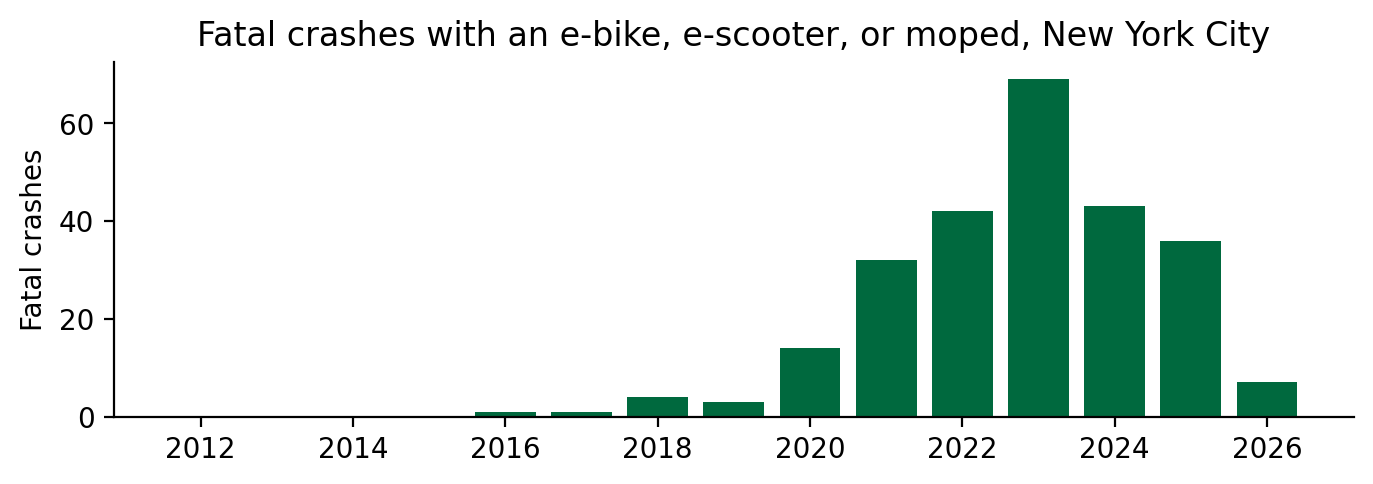

In [61]:
fig, ax = plt.subplots(figsize=(8, 2.3))
ax.bar(question_crashes.index, question_crashes, color='#00693e')
ax.set(ylabel='Fatal crashes',
       title='Fatal crashes with an e-bike, e-scooter, or moped, '
             'New York City')
ax.set_xticks(range(2012, 2027, 2))
ax.spines[['top', 'right']].set_visible(False);

- **69** fatal crashes in 2023, a quarter of that year's 269, then 43 in
  2024 and 36 in 2025. The 2026 bar ends on 4 May.

### ❓ Question

The e-bike rule matches no vehicle before 2019. Did no crash with an e-bike
kill anyone before then?

<details><summary>Answer</summary>

**This table cannot answer that.** A rule finds only the words that officers
typed. The spelling `E-Bik` first appears in 2019 and `E-Bike` in 2020. An
e-bike in an earlier crash may have been typed as `Bike`. Two readings fit:
officers changed how they record e-bikes, or riders moved from pedal bikes
to e-bikes. These records cannot separate the two.

</details>

## The count of fatal crashes, 2016 to May 2026

- With three rules and a check of every spelling, **252** fatal crashes from
  2016 to May 2026 involved an e-bike, an e-scooter, or a moped. The yearly
  count rose from 3 in 2019 to 69 in 2023.
- The exact spelling `E-Bike` alone found 131 vehicles, about half of the 255
  that the three rules matched.

<div class="alert alert-info">

**Key idea.** Test every pattern on values that should match, values that
should not, and the real values it leaves out. Print the matches and the
misses before you count.

</div>

### Rewrite instead of label: `.str.replace` with `regex=True`

The activity standardizes street names, which rewrites values instead of
labeling them. Write every e-scooter spelling as `E-Scooter`, and print each
value that changed, with its count.

In [62]:
types = vehicles['vehicle_type']
rewritten = types.str.replace(r'^E[- ]*SCO.*', 'E-Scooter',
                              case=False, regex=True)
changed = types.notna() & (types != rewritten)
pd.DataFrame({'before': types[changed],
              'after': rewritten[changed]}).value_counts()

before      after    
E SCO       E-Scooter    1
E- SCOOTER  E-Scooter    1
E-SCOOTER   E-Scooter    1
E-Sco       E-Scooter    1
ESCOOTER S  E-Scooter    1
Name: count, dtype: int64

- `.*` after `SCO` takes the rest of the value, so the whole value becomes
  `E-Scooter`. Five spellings change; `E-Scooter` itself does not.
- A rewrite erases the recorded spelling. A false positive changes a value
  for good, so print every value a rule changed, before and after, as here.

## What regular expressions are for

- A regular expression describes the shape of text. One pattern,
  `^E[- ]*BIK` with capitals ignored, matches `E-Bike`, `E-Bik`, and
  `E BIKE`; `==` needs one test per spelling.
- With a pattern, you can find, pull out, rewrite, split, and count parts of
  text. This lecture found email addresses, class years, Social Security
  numbers, HTML tags, and every spelling of five vehicle classes.
- When the text is fixed, a string method is easier to read: `==`, `in`,
  `.startswith`, `.lower`.
- A pattern that sorts records into classes is a measurement rule. The rules
  in this lecture counted motor scooters with mopeds, and left out
  `Standing S`, `SCOOTER`, `ELECT`, and `Pedicab`.

### What we learned: functions and methods

| Goal | Write |
|---|---|
| Swap whole values; edit text inside each value | `s.replace('old', 'new')`; `s.str.replace('old', 'new')` |
| The first match in a string | `re.search(r'...', s)`, then `.group()` and `.start()` |
| Every match in a string, or in each value | `re.findall(r'...', s)`; `s.str.findall(r'...')` |
| Test a column | `.str.contains(r'...', case=False, na=False)` |
| Keep part of each match | `re.findall(r'(\d{2})', s)`; `.str.extract(r'(...)')` |
| Replace or split | `re.sub(r'...', 'new', s)`, `re.split(r'...', s)` |
| Rewrite a column by a pattern | `.str.replace(r'...', 'new', regex=True)` |
| Ignore capitals | `flags=re.IGNORECASE` in `re`; `case=False` in pandas |